# Biblio

In [1]:
import os
import sys
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))

import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import importlib
from utils_files import utils_credit
from utils_files import utils_ai4i
from utils_files import utils_partie3
from utils_files import utils_partie5
import numpy as np

from utils_files import utils_credit
importlib.reload(utils_credit)


<module 'utils_files.utils_credit' from 'c:\\Users\\djidj\\Documents\\m2\\S1\\ML\\TP-Anomalie-ML\\utils_files\\utils_credit.py'>

In [2]:
# Import de nos fonctions utils
sys.path.append(os.path.abspath("."))
from utils_files import utils_credit

print("Pandas version :", pd.__version__)
print("Numpy version  :", np.__version__)

Pandas version : 3.0.5
Numpy version  : 2.5.3


# **PARTIE 2 :**

# 1. Préparer Credit Card

## a. Examiner les données

- Types des colonnes
- Recherche de valeurs manquantes
- Détection et suppression des doublons
- Proportion de fraudes
- Gestion de Time et découpage stratifié (60% Train / 20% Val / 20% Test)

### Examen initial (types, valeurs manquantes, doublons)

In [3]:
# Chargement brut et examen initial (dimensions, valeurs manquantes, doublons, types)
df_raw = utils_credit.examiner_donnees_brutes("../data/creditcard.csv")

=== Examen initial du jeu de données brut ===
Dimensions               : 284807 lignes, 31 colonnes
Valeurs manquantes       : 0
Nombre de doublons       : 1081 (0.38%)
Types de colonnes        : {'float64': 30, 'int64': 1}


### Nettoyage des doublons et calcul du déséquilibre

=== Distribution des classes ===
Transactions normales (0) : 283253 (99.833%)
Fraudes (1)               : 473 (0.167%)
Ratio de déséquilibre     : 1 fraude pour 599 transactions normales


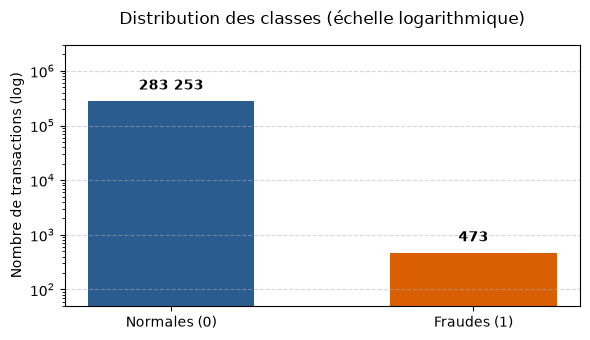

In [4]:
# Nettoyage des doublons et calcul des proportions de classe
df = utils_credit.load_clean_data("../data/creditcard.csv")
utils_credit.afficher_desequilibre_classes(df)

# Graphique du déséquilibre de classe
utils_credit.tracer_distribution_classes(df)

### Découpage stratifié (60% Train / 20% Val / 20% Test)

In [5]:
# Découpage stratifié avec exclusion de 'Time' et 'Class' de X
X_train, X_val, X_test, y_train, y_val, y_test = utils_credit.split_data(df, random_state=42)

utils_credit.verifier_decoupage(y_train, y_val, y_test)

,Partition,Total transactions,Nb fraudes,Taux de fraude
0,Train (60%),170 235,284,0.167%
1,Val (20%),56 745,94,0.166%
2,Test (20%),56 746,95,0.167%


### Analyse de Time et limites du découpage aléatoire

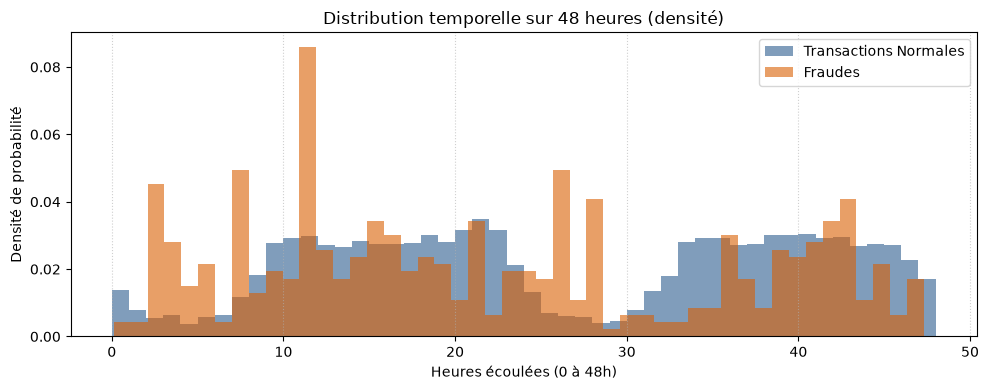

In [6]:
# Visualisation de la distribution temporelle des transactions
utils_credit.tracer_distribution_temporelle(df)

#### Limites du découpage aléatoire par rapport à la variable Time :

1. **Fuite temporelle (Data leakage / interpolation) :**
   Un découpage aléatoire mélange les données du jour 1 et du jour 2. Le modèle risque donc d'apprendre sur des transactions du futur pour prédire des fraudes du passé, ce qui est impossible dans la réalité.

2. **Dérive de concept (Concept Drift) :**
   Les comportements légitimes suivent des cycles jour/nuit (creux la nuit, pics le jour), alors que les méthodes des fraudeurs s'adaptent et évoluent en permanence dans le temps.

3. **Inadéquation avec la production réelle :**
   En conditions réelles dans une banque, on s'entraîne toujours sur le passé ($t < T$) pour prédire sur le futur ($t \ge T$). Un découpage chronologique serait donc indispensable en pratique. Nous écartons `Time` des prédicteurs pour cette comparaison afin d'éviter qu'il n'apprenne des corrélations temporelles factices.


## b. Étude des échelles des variables et prétraitement

### Observer les échelles (Amount vs V1 à V28)

In [7]:
# Comparaison des échelles entre Amount et les composantes ACP V1..V28
utils_credit.analyser_echelles_variables(X_train)

=== Échelle de la variable 'Amount' (Train) ===
Médiane : 22.00 € | Moyenne : 88.30 € | Écart-type : 243.92 €
Min     : 0.00 € | Max     : 18910.00 € | IQR (Q3 - Q1) : 72.04 €

=== Échelle des variables issues de l'ACP (V1 à V28) (Train) ===
Moyenne globale des V_i     : 0.0005 (centrées en 0)
Écart-type moyen des V_i    : 0.9702 (unitaires)
Étendue globale (min / max) : [-73.22 ; 38.12]


### Visualiser la distribution de Amount

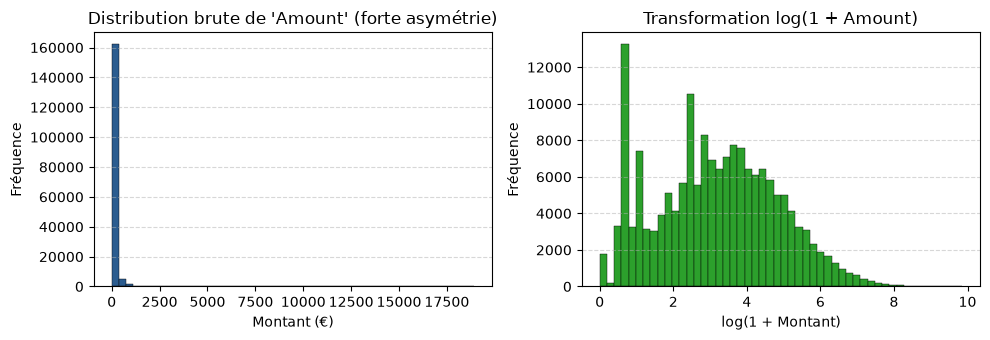

In [8]:
# Distribution brute de Amount vs transformation log(1 + Amount)
utils_credit.tracer_distribution_montant(X_train)

#### Justification du prétraitement par famille d'algorithmes :

1. **Méthodes fondées sur les distances (LOF, k-NN dans SMOTE) :**
   - **Forte sensibilité à l'échelle :** La distance euclidienne calcule la somme des écarts au carré $\sum (x_i - y_i)^2$. Comme `Amount` varie entre 0 et 18 910 € alors que $V_1 \dots V_{28}$ varient entre -5 et +5, la variable `Amount` écraserait toutes les autres composantes.
   - **Pourquoi `RobustScaler` plutôt que `StandardScaler` ?** `StandardScaler` utilise la moyenne et l'écart-type, qui sont très déformés par les montants extrêmes (outliers). `RobustScaler` repose sur la **médiane** et l'**écart interquartile (IQR)**, ce qui le rend résilient aux montants atypiques.

2. **Modèles linéaires (Régression Logistique) :**
   - La régularisation ($L_2$) applique une pénalité uniforme sur les coefficients. Sans mise à l'échelle, le coefficient de `Amount` serait artificiellement écrasé par rapport à ceux des $V_i$.

3. **Modèles arborescents (Arbre de décision, Isolation Forest) :**
   - Ils sont **invariants aux changements d'échelle monotones** car leurs découpages univariés ($X_j \le \theta$) ne dépendent que du rang/ordre des valeurs. La mise à l'échelle ne change pas leurs décisions mais uniformise le pipeline.

4. **Variables $V_1$ à $V_{28}$ :**
   - Issues d'une ACP (PCA), elles sont déjà centrées en 0 et réduites. Étant anonymisées pour préserver le secret bancaire, toute interprétation métier causale est impossible ; nous les conservons donc sans transformation.


### Appliquer la mise à l'échelle (scale_amount) sur Train uniquement

In [9]:
# Mise à l'échelle robuste ajustée strictement sur Train
X_train_s, X_val_s, X_test_s = utils_credit.scale_amount(X_train, X_val, X_test)
utils_credit.verifier_mise_a_echelle(X_train_s)

=== Vérification de 'Amount' après RobustScaler (Train) ===
Médiane (doit être 0.0)  : 0.0000
Q1 (-0.227 typique)      : -0.2275
Q3 (+0.773 typique)      : 0.7725
IQR normalisé (Q3 - Q1)  : 1.0000 (égal à 1.0)
Min / Max                : [-0.305 ; 262.206]


### Boxplot Avant vs Après RobustScaler

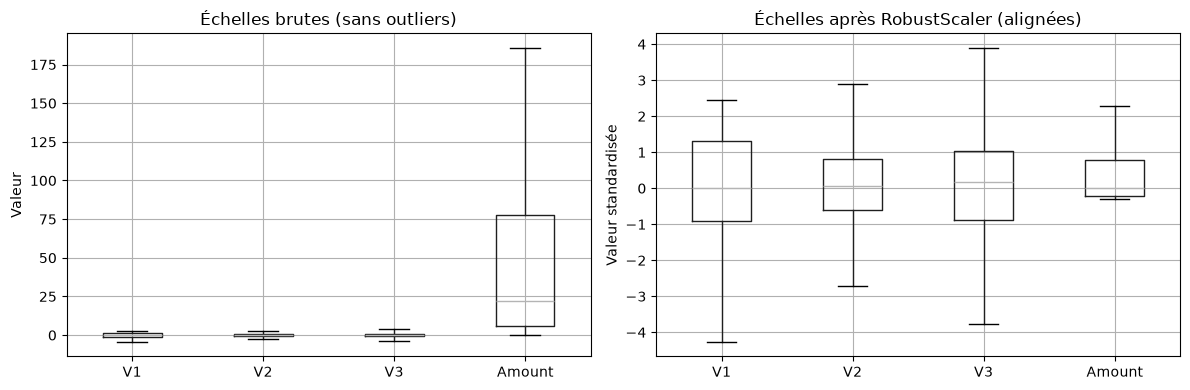

In [10]:
utils_credit.tracer_boxplots_comparatifs(X_train, X_train_s)

# 2. Comparer et prendre une décision

## a. Comparaison des modèles supervisés (Arbre de décision et Régression Logistique)


Pour chaque modèle, nous étudions 3 variantes :
1. Sans correction du déséquilibre
2. Avec pondération des classes (`class_weight='balanced'`)
3. Avec rééchantillonnage **SMOTE** (justifié par la création de données synthétiques fiables grâce à notre mise à l'échelle préalable).

Le rééchantillonnage est appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`, `y_train`).

### **Justification du choix de la méthode de rééchantillonnage (SMOTE) :**

Parmi les méthodes proposées par le sujet, nous avons retenu **SMOTE** pour les raisons suivantes :
- **RandomUnderSampler** élimine aléatoirement plus de 99% des transactions normales, ce qui détruit une quantité massive d'informations représentatives.
- **RandomOverSampler** duplique à l'identique les mêmes fraudes existantes, favorisant le surapprentissage (*overfitting*).
- **Tomek Links** ne fait qu'un nettoyage frontière sans corriger le ratio extrême de 1 fraude pour 600 normales.
- **SMOTE (Synthetic Minority Over-sampling Technique)** génère de nouvelles fraudes synthétiques intelligentes par interpolation entre voisins réels dans l'espace des descripteurs. Notre mise à l'échelle préalable (`RobustScaler`) garantit que le calcul des plus proches voisins (k-NN) dans SMOTE est mathématiquement fiable et équilibré.

> **Règle méthodologique :** SMOTE est ajusté et appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`). Les partitions de validation et de test restent dans leur distribution déséquilibrée réelle.

### Créer le jeu rééchantillonné avec SMOTE

In [11]:
# Application de SMOTE uniquement sur le jeu d'entraînement
X_train_smote, y_train_smote = utils_credit.appliquer_smote(X_train_s, y_train)

Effectifs Train initial : 170235 dont 284 fraudes
Effectifs Train SMOTE   : 339902 dont 169951 fraudes


### Évaluer la Régression Logistique (3 variantes)

Régression Logistique : Comparaison des 3 variantes


,Modèle,AP (Validation),AUC-ROC
0,LR (Sans correction),0.6968,0.9697
1,LR (Pondération classes),0.6927,0.9713
2,LR (SMOTE),0.6905,0.9700


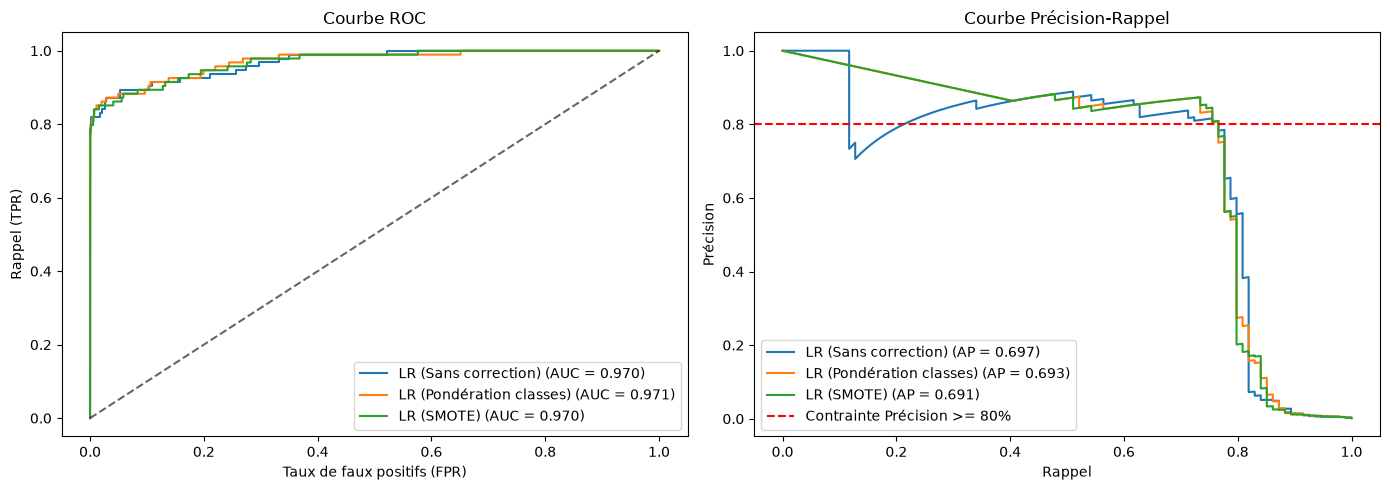

In [12]:
# Évaluation et comparaison des 3 variantes de Régression Logistique
df_res_lr, scores_lr_dict, modeles_lr = utils_credit.evaluer_variantes_supervisees(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val, type_modele="lr"
)

### Évaluer l'Arbre de Décision (3 variantes)

Arbre de Décision : Comparaison des 3 variantes


,Modèle,AP (Validation),AUC-ROC
0,Arbre (Sans correction),0.6684,0.8563
1,Arbre (Pondération classes),0.4343,0.8878
2,Arbre (SMOTE),0.3420,0.9628


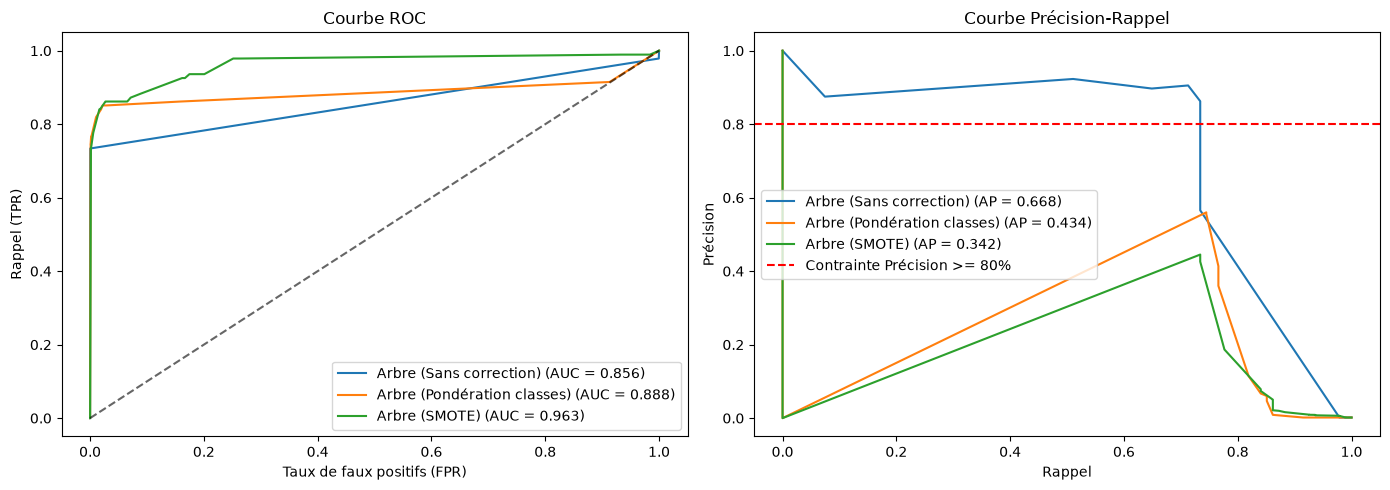

In [13]:
# Évaluation et comparaison des 3 variantes de l'Arbre de Décision
df_res_dt, scores_dt_dict, modeles_dt = utils_credit.evaluer_variantes_supervisees(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val, type_modele="arbre"
)

### Comparaison des 6 variantes juste avec AP et AUC-ROC

> Dans les consignes on a : 

L’AP est la mesure principale de classement : elle résume la relation entre rappel des anomalies et précision des alertes.
Ici on fait la comparaison sans seuil optimal

Classement des modèles selon : AP (Validation)


,Rang,Modèle,AP (Validation),AUC-ROC
0,1,LR (Sans correction),0.6968,0.9697
1,2,LR (Pondération classes),0.6927,0.9713
2,3,LR (SMOTE),0.6905,0.9700
3,4,Arbre (Sans correction),0.6684,0.8563
4,5,Arbre (Pondération classes),0.4343,0.8878
5,6,Arbre (SMOTE),0.3420,0.9628


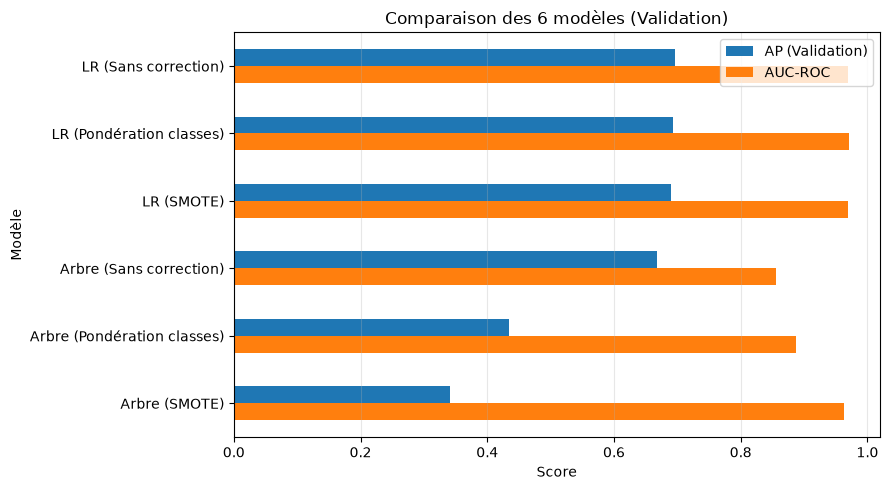


Meilleure variante par famille :
  Arbre -> Sans correction (AP (Validation) = 0.6684)
  LR -> Sans correction (AP (Validation) = 0.6968)

Meilleur modèle global : LR (Sans correction)


In [14]:
df_comparaison, meilleur_modele = utils_credit.comparer_modeles(df_res_lr, df_res_dt)

## b. Sélection des hyperparamètres (6 configurations par modèle)

Conformément aux consignes, nous testons au maximum 6 configurations par modèle :
- **Régression Logistique :** 2 valeurs de régularisation ($C=0.01$ et $C=1.0$) pour chacune des 3 variantes de déséquilibre (Sans correction, Balanced, SMOTE).
- **Arbre de décision :** 2 profondeurs maximales (`max_depth=5` et `max_depth=10`) pour chacune des 3 variantes. Des profondeurs limitées permettent de régulariser l'arbre et d'éviter le surapprentissage.

> Dans les consignes on a : 

- Pour chaque configuration, cherchez sur la validation le seuil donnant le meilleur rappel parmi ceux qui satisfont la contrainte et produisent au moins une alerte. En cas d’égalité, privilégiez la précision, puis l’AP. Signalez le nombre d’alertes soutenant le résultat : une précision élevée sur très peu de cas est fragile.

- Si aucune configuration ne satisfait la contrainte, indiquez « objectif non atteint » et présentez le meilleur compromis observé sans abaisser silencieusement l’exigence. Figez ensuite le modèle et le seuil avant le test. Rapportez la précision et le rappel obtenus sur le test, même si la contrainte n’y est plus respectée.

### Tester les 6 configurations de la Régression Logistique

Régression Logistique : Évaluation des 6 configurations


,C,Variante,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées),TP (Fraudes détectées),TN (Normales correctes)
1,1.00,Sans correction,0.6968,0.9697,Atteint,0.075610,0.8090,0.7660,0.7869,0.8828,17,22,72,56634
3,1.00,Pondération,0.6927,0.9713,Atteint,0.999994,0.8090,0.7660,0.7869,0.8828,17,22,72,56634
5,1.00,SMOTE,0.6905,0.9700,Atteint,0.999998,0.8090,0.7660,0.7869,0.8828,17,22,72,56634
0,0.01,Sans correction,0.6857,0.9750,Atteint,0.083164,0.8000,0.7234,0.7598,0.8616,17,26,68,56634
4,0.01,SMOTE,0.6784,0.9698,Atteint,0.999996,0.8276,0.7660,0.7956,0.8828,15,22,72,56636
2,0.01,Pondération,0.6696,0.9711,Atteint,0.999991,0.8161,0.7553,0.7845,0.8775,16,23,71,56635


MEILLEUR MODÈLE LR : C=0.01, SMOTE
   Respecte contrainte (Précision >= 80%)
   Alertes      : 87
   AP           : 0.6784
   AUC-ROC      : 0.9698
   Seuil optimal: 1.0000
   Précision    : 0.8276 (contrainte >= 0.80)
   Rappel       : 0.7660
   F1-score     : 0.7956


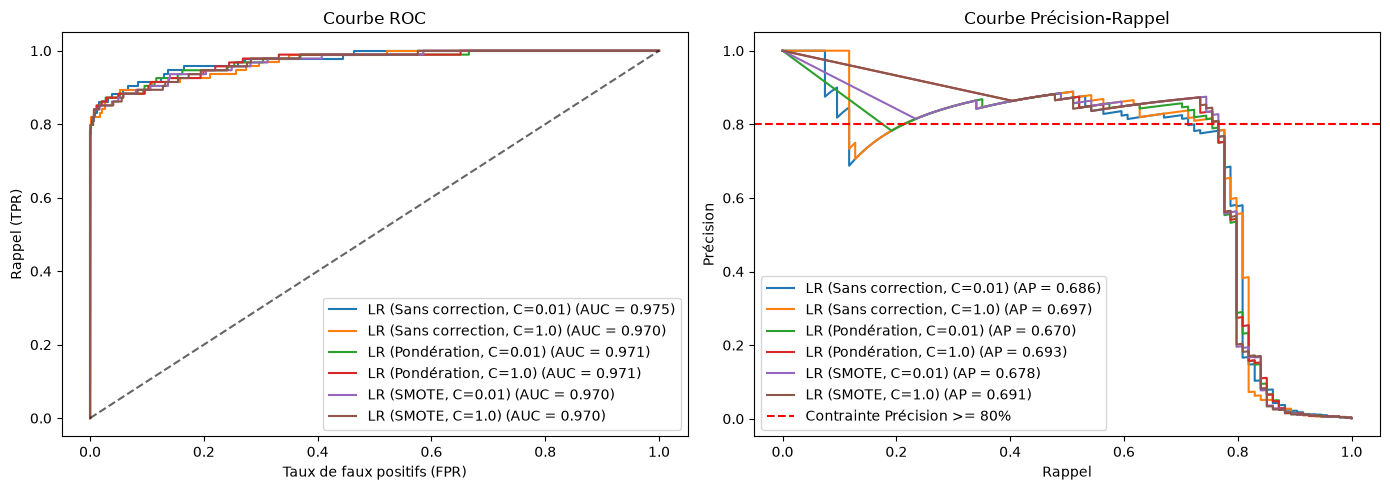

In [15]:
# Évaluation des 6 configurations de Régression Logistique (C in {0.1, 1.0} x 3 variantes)
df_eval_lr, scores_6_lr = utils_credit.evaluer_grille_lr(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val
)

# Tracé des courbes ROC et Précision-Rappel des 6 configurations
utils_credit.tracer_courbes_roc_pr(y_val, scores_6_lr)


### Tester les 6 configurations de l'Arbre de Décision

Arbre de Décision : Évaluation des 6 configurations


,Profondeur,Variante,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées),TP (Fraudes détectées),TN (Normales correctes)
0,5,Sans correction,0.6684,0.8563,Atteint,0.050000,0.8625,0.7340,0.7931,0.8669,11,25,69,56640
1,10,Sans correction,0.5929,0.8321,Atteint,1.000000,0.8750,0.6702,0.7590,0.8350,9,31,63,56642
3,10,Pondération,0.4369,0.8822,Non atteint,0.999104,0.5812,0.7234,0.6445,0.8613,49,26,68,56602
2,5,Pondération,0.4343,0.8878,Non atteint,0.998761,0.5600,0.7447,0.6393,0.8719,55,24,70,56596
5,10,SMOTE,0.3609,0.8327,Non atteint,0.999371,0.4928,0.7234,0.5862,0.8611,70,26,68,56581
4,5,SMOTE,0.3420,0.9628,Non atteint,0.998291,0.4452,0.7340,0.5542,0.8663,86,25,69,56565


MEILLEUR MODÈLE ARBRE : Profondeur=5, Sans correction
   Respecte contrainte (Précision >= 80%)
   Alertes      : 80
   AP           : 0.6684
   AUC-ROC      : 0.8563
   Seuil optimal: 0.0500
   Précision    : 0.8625 (contrainte >= 0.80)
   Rappel       : 0.7340
   F1-score     : 0.7931


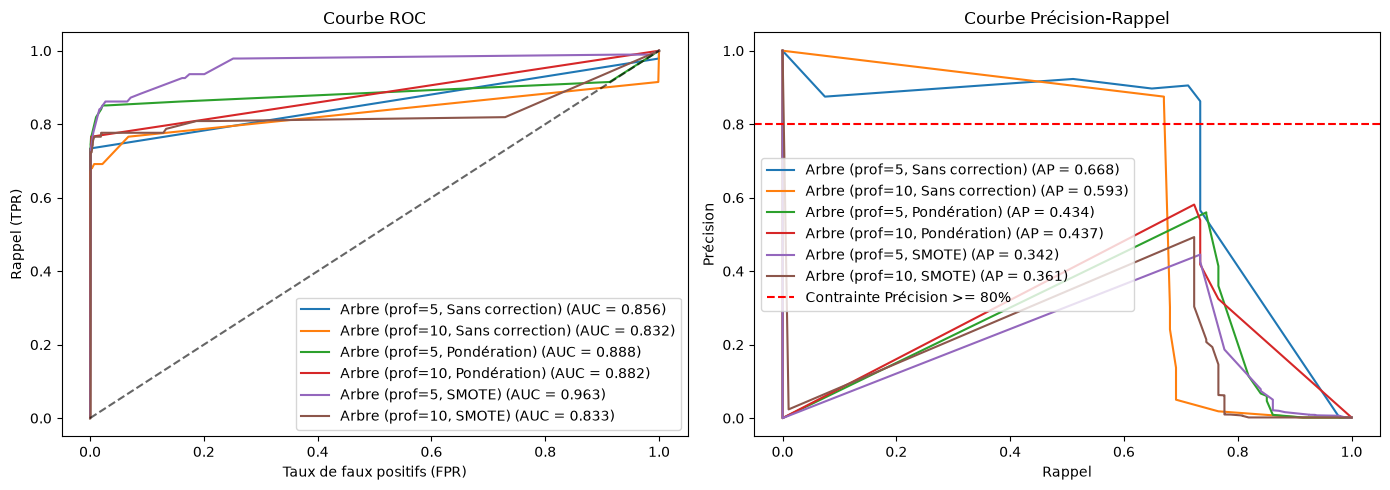

In [16]:
# Évaluation des 6 configurations de l'Arbre de Décision (max_depth in {3, 5} x 3 variantes)
df_eval_dt, scores_6_dt = utils_credit.evaluer_grille_arbre(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val
)

# Tracé des courbes ROC et Précision-Rappel des 6 configurations de l'Arbre
utils_credit.tracer_courbes_roc_pr(y_val, scores_6_dt)


### Justification des configurations testées et sélection du meilleur modèle :

#### 1. Justification des hyperparamètres choisis (6 configurations par modèle) :

   - **Régression Logistique :** Nous explorons le paramètre de régularisation 
     $C \in \{0.01, 1.0\}$ sur les 3 variantes de déséquilibre ($2 \times 3 = 6$ configs).
     • C=0.01 : régularisation FORTE → coefficients stables mais potentiellement biaisés
     • C=1.0 : régularisation MODÉRÉE (défaut) → meilleur compromis flexibilité/stabilité
     
   - **Arbre de Décision :** Nous testons deux profondeurs $\text{max\_depth} \in \{5, 10\}$ 
     sur les 3 variantes ($2 \times 3 = 6$ configs). Pour 284k lignes :
     • depth=5 : très conservateur, risque d'underfitting
     • depth=10 : modéré, capte la complexité sans surapprendre

2. **Sélection du meilleur modèle :**
   - Parmi les modèles respectant Précision ≥ 80%, on prend celui avec le meilleur AP
   - Si aucun ne respecte la contrainte, on signale "objectif non atteint" 
     et on prend le meilleur compromis observé

#### 2. Tableau récapitulatif 

In [17]:
# Après evaluer_grille_lr() et evaluer_grille_arbre()
modele_final, type_modele = utils_credit.recapitulatif_section_2b(df_eval_lr, df_eval_dt)

RÉCAPITULATIF SECTION 2.b - COMPARAISON DES 12 CONFIGURATIONS

TABLEAU COMPARATIF FINAL (Meilleur de chaque famille)


,Modèle,Config,AP,AUC-ROC,Seuil,Précision,Rappel,F1-score
0,Régression Logistique,"C=0.01, SMOTE",0.6784,0.9698,0.999996,0.8276,0.766,0.7956
1,Arbre de Décision,"depth=5, Sans correction",0.6684,0.8563,0.050000,0.8625,0.734,0.7931


GAGNANT FINAL : Régression Logistique (Rappel=0.7660, Précision=0.8276, AP=0.6784)


## c. Modèles non supervisés : Isolation Forest et Local Outlier Factor (LOF)

Nous entraînons ces deux modèles de façon purement non supervisée (sans utiliser les étiquettes y_train et sans rééchantillonnage).

Pour LOF, nous utilisons novelty=True : le modèle est ajusté sur un sous-échantillon aléatoire de 30 000 transactions du Train (le coût de LOF croît en $O(N^2)$), puis sert uniquement à scorer les jeux de Validation et de Test. Isolation Forest, lui, est ajusté sur l'ensemble du Train. Les observations d'entraînement ne sont pas réévaluées en mode novelty.

Conformément au protocole, nous harmonisons les scores en inversant leur signe (-score_samples) pour qu'une valeur plus élevée indique systématiquement une observation plus suspecte.

### Entraînement et Évaluation complète d'Isolation Forest et LOF

In [18]:
importlib.reload(utils_credit)

# IF ajusté sur tout le Train ; LOF (novelty=True) ajusté sur un sous-échantillon de 30 000 transactions ; seuils calibrés sur la Validation
idx_lof = np.random.default_rng(42).choice(len(X_train_s), size=30000, replace=False)
X_train_lof = np.asarray(X_train_s)[idx_lof]

# Le nombre de fraudes présentes dans ce sous-échantillon est affiché à titre de contrôle : il n'intervient ni dans le tirage, ni dans l'ajustement.
print("Fraudes dans le sous-échantillon LOF :", int(np.asarray(y_train)[idx_lof].sum()))

df_eval_non_sup, scores_non_sup_dict, detecteurs = utils_credit.entrainer_modeles_non_supervises(
    X_train_s, X_val_s, y_val, X_train_lof=X_train_lof, random_state=42, min_precision=0.80
)

Fraudes dans le sous-échantillon LOF : 42
--- Entraînement des détecteurs non supervisés (sans étiquettes) ---
Entraînement de Isolation Forest (6 configurations, 170235 transactions)...
Entraînement de Local Outlier Factor (LOF) (6 configurations, 30000 transactions)...
Grille des configurations (AP sur la Validation, sélection des hyperparamètres)


,Modèle,n_estimators,max_samples,AP (Validation),n_neighbors
0,Isolation Forest,100.0,256.0,0.0861,NaN
1,Isolation Forest,100.0,1024.0,0.1516,NaN
2,Isolation Forest,100.0,2048.0,0.1422,NaN
3,Isolation Forest,200.0,256.0,0.0904,NaN
4,Isolation Forest,200.0,1024.0,0.1463,NaN
5,Isolation Forest,200.0,2048.0,0.1473,NaN
6,Local Outlier Factor (LOF),NaN,NaN,0.0027,10.0
7,Local Outlier Factor (LOF),NaN,NaN,0.0116,20.0
8,Local Outlier Factor (LOF),NaN,NaN,0.3178,50.0
9,Local Outlier Factor (LOF),NaN,NaN,0.4060,100.0



Détecteurs non supervisés : Résultats sur la Validation (meilleure configuration par modèle)


,Modèle,Hyperparamètres,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées),TP (Fraudes détectées),TN (Normales correctes)
0,Isolation Forest,"n_estimators=100, max_samples=1024",0.1516,0.9452,Non atteint,0.633711,0.2329,0.3617,0.2833,0.6799,112,60,34,56539
1,Local Outlier Factor (LOF),n_neighbors=100,0.4060,0.9470,Non atteint,2.674428,0.5278,0.6064,0.5644,0.8027,51,37,57,56600


MEILLEUR MODÈLE NON SUPERVISÉ : Local Outlier Factor (LOF)
   Objectif non atteint (aucune config avec Précision >= 80%)
   Alertes      : 108
   AP           : 0.4060
   AUC-ROC      : 0.9470
   Seuil optimal: 2.6744
   Précision    : 0.5278
   Rappel       : 0.6064
   F1-score     : 0.5644



Détecteurs non supervisés : Résultats sur la Validation


,Modèle,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées)
0,Isolation Forest,0.1516,0.9452,Non atteint,0.633711,0.2329,0.3617,0.2833,0.6799,112,60
1,Local Outlier Factor (LOF),0.4060,0.9470,Non atteint,2.674428,0.5278,0.6064,0.5644,0.8027,51,37


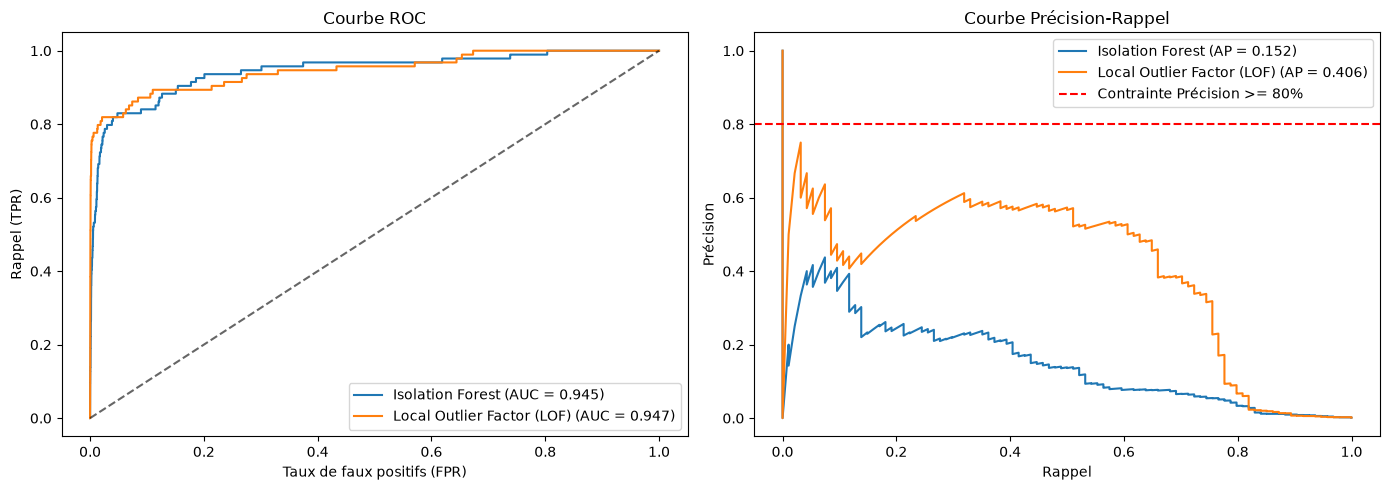

In [19]:
# Tableau récapitulatif
colonnes_ordre = [
    "Modèle",
    "AP",
    "AUC-ROC",
    "Contrainte (>=80%)",
    "Seuil",
    "Précision",
    "Rappel",
    "F1-score",
    "Balanced Accuracy",
    "FP (Fausses alertes)",
    "FN (Fraudes manquées)",
]
print("\nDétecteurs non supervisés : Résultats sur la Validation")
display(df_eval_non_sup[colonnes_ordre])

# Tracé des courbes ROC et Précision-Rappel
utils_credit.tracer_courbes_roc_pr(y_val, scores_non_sup_dict)

## d. Distinction entre ajustement non supervisé et sélection supervisée des réglages

**1. L'ajustement du détecteur (sans étiquettes)**

Isolation Forest et LOF sont entraînés uniquement sur les caractéristiques des transactions, jamais sur le fait qu'elles soient des fraudes ou non. Isolation Forest est ajusté sur tout le Train ; LOF est ajusté sur un sous-échantillon aléatoire de 30 000 transactions du Train, pour limiter le temps de calcul. Ils apprennent à quoi ressemblent les transactions « normales » : Isolation Forest vérifie à quel point un point est facile à isoler, LOF regarde s'il est dans une zone peu dense par rapport à ses voisins. Un point difficile à classer dans la masse reçoit un score d'anomalie élevé.

**2. Le choix des hyperparamètres (avec étiquettes)**

Isolation Forest (`n_estimators`, `max_samples`) et LOF (`n_neighbors`) ont plusieurs réglages possibles. Nous testons une grille de 6 configurations pour chacun et retenons celle qui obtient la meilleure AP sur le jeu de **validation**. Ce choix utilise donc les étiquettes de validation : il est supervisé.

**3. La sélection du seuil (avec étiquettes)**

Le modèle donne un score à chaque transaction, mais il faut encore décider à partir de quel score on déclenche une alerte. Ce choix utilise aussi les étiquettes de **validation** : pour chaque seuil possible, on compte les alertes justes. On retient le seuil qui maximise le rappel tout en gardant la précision d'au moins 80 %, c'est-à-dire au moins 4 alertes sur 5 qui sont de vraies fraudes.

Ainsi, seul l'ajustement du détecteur est non supervisé : la chaîne complète (choix des hyperparamètres et du seuil) est supervisée.

> **Conséquence** : les performances mesurées sur la validation sont optimistes pour la configuration retenue, puisqu'elle a été choisie sur ce même jeu.

> **Le jeu de test** : il n'est utilisé qu'à la fin, pour mesurer la performance finale. S'il servait à choisir les réglages ou le seuil, le résultat serait trop optimiste.

# 3. Évaluer les scores et fixer le seuil 

## a&b. Comparaison avec seuil defaut pour chaque modele

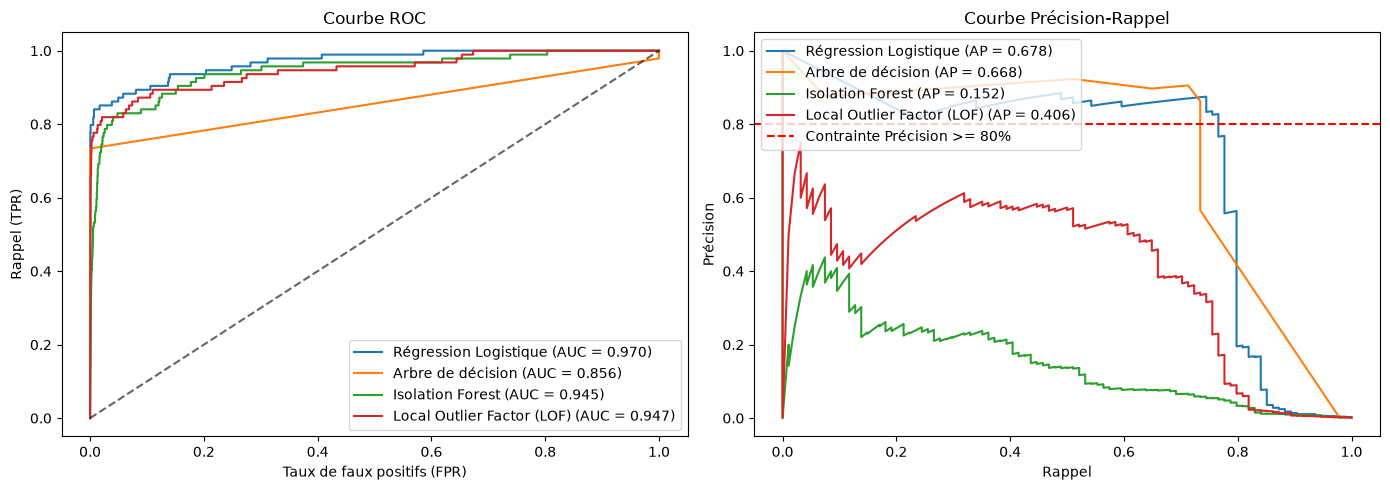

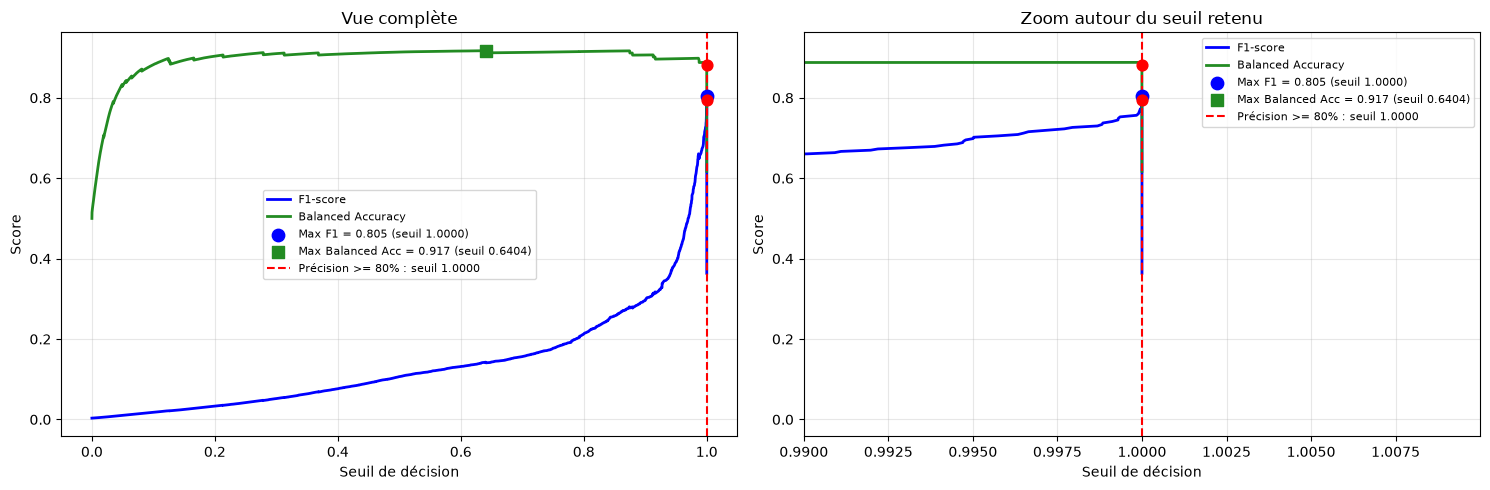

,Modèle,Configuration,AP (Validation),AUC-ROC (Validation)
0,Régression Logistique,"C=0.01, avec SMOTE",0.6784,0.9698
1,Arbre de décision,"max_depth=5, sans correction",0.6684,0.8563
2,Local Outlier Factor (LOF),n_neighbors=100,0.4060,0.9470
3,Isolation Forest,"n_estimators=100, max_samples=1024",0.1516,0.9452


,Modèle,Seuil par défaut,Précision (défaut),Rappel (défaut),Seuil optimal,Précision (optimal),Rappel (optimal),Contrainte (>=80%)
0,Régression Logistique,0.5,0.0569,0.8511,0.999996,0.8276,0.7660,Atteint
1,Arbre de décision,0.5,0.9054,0.7128,0.050000,0.8625,0.7340,Atteint
2,Isolation Forest,0.5,0.0625,0.7234,0.633711,0.2329,0.3617,Non atteint
3,Local Outlier Factor (LOF),1.5,0.0421,0.8191,2.674428,0.5278,0.6064,Non atteint


In [20]:
importlib.reload(utils_credit)
tableau_3a, seuils_3a = utils_credit.partie_3a(
    y_val, scores_6_lr, scores_6_dt, scores_non_sup_dict, df_eval_non_sup
)
display(tableau_3a)
display(seuils_3a)

> **Règle de décision.** Le seuil retenu pour chaque modèle est celui qui maximise le rappel sous la contrainte de précision ≥ 80 % (colonne « Seuil optimal »). La régression logistique et l'arbre atteignent cette contrainte. Pour l'Isolation Forest et le LOF, elle n'est pas atteinte : leur seuil « optimal » est le seuil de repli qui maximise le F1, et il ne répond donc pas à la règle.

> **Comparaison au seuil par défaut.** Pour la régression logistique, le seuil par défaut 0,5 donne une précision très faible (0,0569) malgré un rappel élevé (0,8511). Au seuil optimal (0,999996), la précision passe à 0,8276 pour un rappel de 0,7660 : le seuil par défaut n'est pas utilisable après SMOTE. Pour l'arbre, le seuil par défaut 0,5 donne déjà une précision élevée (0,9054) ; le seuil optimal (0,05) apporte un léger gain de rappel (0,7340 contre 0,7128) pour une précision légèrement plus basse. Pour l'IF et le LOF, le seuil par défaut donne une précision très faible, et le seuil de repli améliore la précision sans atteindre la contrainte.

> **Gel des choix.** Le modèle retenu, la Régression Logistique (C=0,01, SMOTE), et son seuil ont été fixés sur la validation. Les autres modèles (arbre de profondeur 5, Isolation Forest, LOF) sont évalués avec leur seuil de validation uniquement à titre de comparaison ; ils ne sont pas retenus, et aucun choix n'a été modifié après avoir vu les résultats du test.

### Justification "Pourquoi les pics de F1 et de Balanced Accuracy ne coïncident pas avec l'objectif métier" :

Les seuils qui maximisent le F1 ou la balanced accuracy ne correspondent pas nécessairement à l'objectif opérationnel, qui est de maximiser le rappel sous la contrainte précision ≥ 80 %. 

Le **F1** pondère précision et rappel de façon symétrique et ne contient aucune contrainte : son maximum peut se situer à une précision inférieure à 80 % (c'est le cas pour IF et LOF, avec des précisions de 0,23 et 0,53 au seuil de repli, qui est le maximum du F1) ou supérieure, auquel cas on pourrait gagner du rappel. Pour la LR, les deux seuils sont ici proches, mais rien ne le garantit. 

La **balanced accuracy** moyenne le rappel des fraudes et celui des normales. Les normales étant très largement majoritaires, la spécificité reste proche de 1 même avec plusieurs centaines de fausses alertes (100 fausses alertes ne représentent que 0,2 % des normales). La balanced accuracy reste donc élevée sur presque tout l'axe et son maximum, peu informatif, ne tient pas compte de la fiabilité des alertes : il peut correspondre à une précision très inférieure à 80 %. 

L'**AUC-ROC** souffre du même défaut : le taux de faux positifs est dilué dans la masse des transactions normales, donc l'AUC reste élevée même quand la précision est faible (l'arbre a une AUC de 0,856 pour une AP proche de celle de la LR, et l'IF une AUC de 0,945 pour une AP de 0,152). C'est pourquoi l'average precision, qui s'appuie sur la précision et le rappel, est la mesure principale de comparaison : la précision mesure la part de vraies fraudes parmi les alertes, donc chaque faux positif pèse fortement quand les fraudes sont rares.

## c : Évaluation finale sur l'ensemble de Test

In [21]:
tableau_3c = utils_credit.partie_3c(X_train_s, y_train, X_test_s, y_test, X_train_lof, detecteurs, seuils_3a)
display(tableau_3c)

Effectifs Train initial : 170235 dont 284 fraudes
Effectifs Train SMOTE   : 339902 dont 169951 fraudes


,Modèle,Méthode,Prétraitement,Traitement du déséquilibre,AP,AUC-ROC,Seuil retenu,Précision,Rappel,F1-score,Balanced Accuracy,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées),TN (Normales correctes),Temps entraînement (s),Sélectionné (validation)
0,Régression Logistique,Régression Logistique (C=0.01),RobustScaler sur Amount,SMOTE (Train),0.7098,0.9677,0.999996,0.8795,0.7684,0.8202,0.8841,73,10,22,56641,1.56,Oui
1,Arbre de décision,Arbre de décision (max_depth=5),RobustScaler sur Amount,Aucun,0.7403,0.8789,0.050000,0.8523,0.7895,0.8197,0.8946,75,13,20,56638,3.13,
2,Isolation Forest,"Isolation Forest (n_estimators=100, max_sample...",RobustScaler sur Amount,Aucun (non supervisé),0.2668,0.9590,0.633711,0.2323,0.3789,0.2880,0.6884,36,119,59,56532,0.52,
3,Local Outlier Factor (LOF),LOF (n_neighbors=100),RobustScaler sur Amount,Aucun (non supervisé),0.5031,0.9554,2.674428,0.5470,0.6737,0.6038,0.8364,64,53,31,56598,2.25,


Le modèle retenu sur la validation est la **Régression Logistique ($C=0.01$, SMOTE sur le Train)**. Il est sélectionné parce qu'il atteint la contrainte de précision ≥ 80 % avec le rappel optimal le plus élevé (colonne « Sélectionné (validation) »). Son seuil opérationnel est lu dans seuils_3a, calibré uniquement sur l'ensemble de Validation.

Nous les appliquons pour la première fois sur l'ensemble de **Test** (`X_test_s`, `y_test`) pour mesurer la performance réelle en conditions de production.

## d. Interprétation métier concrète des résultats (sur le jeu de Test)

> **Interprétation opérationnelle sur le Test.** Avec le seuil fixé sur la validation, la Régression Logistique déclenche 83 alertes, dont 73 sont de vraies fraudes (TP) et 10 sont des fausses alertes (FP). Sur les 95 fraudes de l'ensemble de Test, 73 sont détectées et 22 échappent à la détection (FN). Les transactions normales correctement classées (TN) ne sont pas affectées par ces alertes.

> En pratique, un analyste devrait examiner 83 transactions pour traiter 73 fraudes, soit environ 88 % d'alertes justifiées. Le coût de cette précision est de laisser passer près d'une fraude sur quatre (23 %). Ce compromis découle directement du seuil choisi sur la validation pour respecter la contrainte de précision ≥ 80 %.

> **Respect de la contrainte.* La précision mesurée sur le Test est de 0,88, donc la contrainte ≥ 80 % est respectée. Le seuil n'a été modifié à aucun moment après avoir vu les résultats du Test.

> **Point de vigilance.** Sur le Test, l'arbre de décision atteint un rappel légèrement supérieur (0,79 contre 0,77, soit 75 fraudes détectées contre 73) mais génère plus de fausses alertes (13 contre 10). Avec seulement 95 fraudes, l'écart d'environ deux détections ne suffit pas à remettre en cause la sélection faite sur la validation. Nous le signalons pour rester transparents sur les compromis, sans changer le choix.

# **Partie 3 :**

# Rechercher une nouvelle méthode — EasyEnsemble de la bibliothèque imbalanced-learn

## a. Choix de la méthode

> **Nous avons retenu EasyEnsemble (Liu, Wu & Zhou, 2009).**

Elle répond directement au problème du TP : 
- les fraudes représentent 0,17 % des transactions. Au lieu de supprimer des normales au hasard une seule fois, elle entraîne plusieurs modèles sur des sous-échantillons équilibrés, puis moyenne leurs prédictions. On exploite ainsi toute la classe majoritaire sans que le déséquilibre domine l'apprentissage.

## b. Référence, principe, hypothèses, score

> Référence : Liu, X.-Y., Wu, J., & Zhou, Z.-H. (2009). « Exploratory Undersampling for Class-Imbalance Learning ». IEEE Transactions on Systems, Man, and Cybernetics, Part B, 39(2), 539-550. Documentation d'implémentation : imbalanced-learn, EasyEnsembleClassifier.

> **Principe :** On tire T sous-échantillons aléatoires de la classe majoritaire, chacun de la taille de la classe minoritaire (les fraudes). Chaque sous-ensemble est combiné avec toutes les fraudes pour former un jeu d'entraînement équilibré. Sur chaque jeu, on entraîne un AdaBoost, dont le apprenant de base est un arbre de décision de profondeur 1 (souche) par défaut. Les T modèles ainsi obtenus sont ensuite agrégés.

> **Hypothèses :**
> - Les étiquettes de fraude sont fiables : la méthode est supervisée et s'appuie sur les fraudes connues.
> - Les fraudes du jeu d'entraînement sont représentatives de l'ensemble des fraudes.
> - Les normales sont suffisamment variées pour qu'un sous-échantillon capture l'essentiel de leur structure; moyenner plusieurs sous-échantillons compense la perte d'information.
> - Les données d'entraînement et de test suivent la même distribution (i.i.d.).

> **Construction du score :** pour chaque transaction $x$, le score est la moyenne des scores de fraude produits par les $T$ AdaBoost, où $T$ est le nombre de sous-ensembles (`n_estimators`) :

$$
s(x) = \frac{1}{T} \sum_{t=1}^{T} P_t(y = 1 \mid x)
$$

> Ces valeurs ne sont pas des probabilités calibrées : elles servent à ordonner les transactions. Le seuil est fixé sur la validation selon la règle de la partie 3.a, puis gelé et appliqué au test sans modification.

## c. Intérêt attendu sur Credit Card + Hyperparamètres importants

> **Intérêt attendu sur Credit Card.** Le jeu Credit Card contient environ 284 000 transactions, dont 492 fraudes, soit moins de 0,2 %. Dans ce contexte, un classifieur entraîné sur l'ensemble déséquilibré risque de ne presque jamais prédire la fraude. EasyEnsemble répond à ce problème en tirant plusieurs sous-ensembles équilibrés : chacun conserve toutes les fraudes et un nombre égal de transactions normales. Chaque sous-ensemble est utilisé pour entraîner un AdaBoost, puis les prédictions sont moyennées. On exploite ainsi l'information de toute la classe majoritaire sans en perdre une grande partie, contrairement à un sous-échantillonnage unique, et la variance est réduite grâce à la moyenne. On attend donc une meilleure détection des fraudes qu'avec les méthodes non supervisées, qui n'utilisent pas les étiquettes.

**Hyperparamètres importants :**

> ***n_estimators*** : le nombre de sous-ensembles équilibrés, donc le nombre de modèles moyennés. Une valeur faible réduit le temps de calcul mais augmente la variance des scores ; une valeur élevée stabilise les scores à coût plus élevé. Nous comparons 5, 10 et 20 sous-ensembles.

> ***sampling_strategy*** : le rapport entre la classe minoritaire et la classe majoritaire dans chaque sous-ensemble. La valeur par défaut 'auto' équilibre les classes à 1:1. Un rapport plus faible garde plus de transactions normales et peut réduire les fausses alertes, au prix d'un entraînement moins équilibré.

## 3.d Entraînement des 3 Configurations de EasyEnsemble

,Modèle,Sous-ensembles,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,AP,AUC-ROC,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées),Temps Train (s)
0,EasyEnsemble (5 sous-ensembles),5,Atteint,0.664042,0.8125,0.6915,0.7471,0.6696,0.9646,65,15,29,0.80
1,EasyEnsemble (10 sous-ensembles),10,Atteint,0.667325,0.8289,0.6702,0.7412,0.6676,0.9646,63,13,31,1.39
2,EasyEnsemble (20 sous-ensembles),20,Atteint,0.656471,0.8000,0.6809,0.7356,0.6607,0.9651,64,16,30,2.88


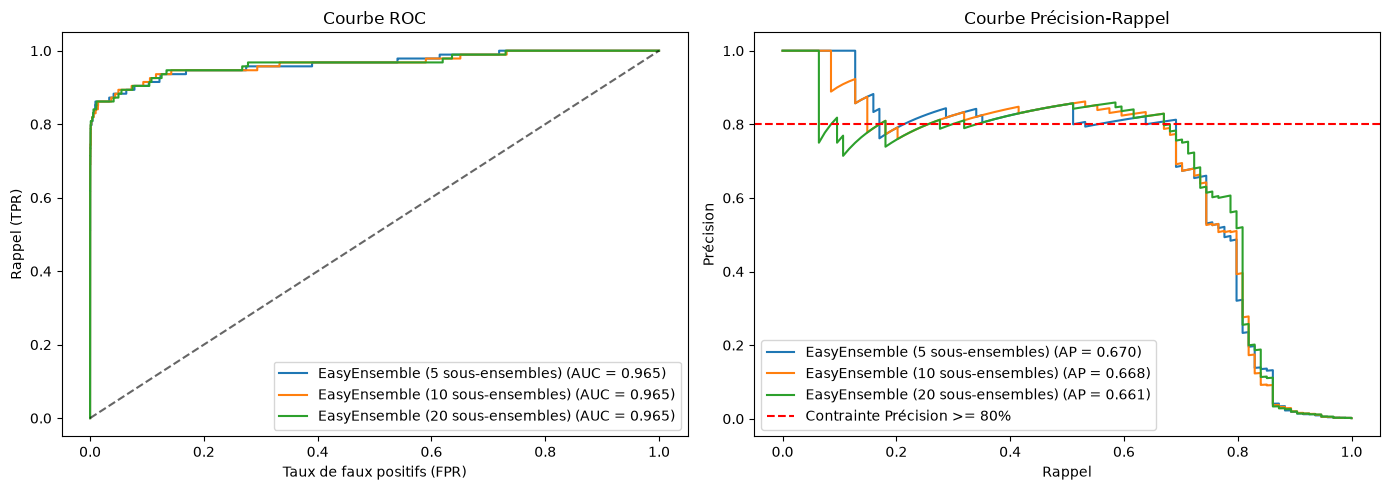

In [22]:
from utils_files import utils_partie3
import importlib
importlib.reload(utils_partie3)

tableau_ee, scores_val_ee, modeles_ee = utils_partie3.entrainer_evaluer_easyensemble(
    X_train_s, y_train, X_val_s, y_val
)
display(tableau_ee)

# 2. Tracé comparatif ROC et Précision-Rappel 
utils_credit.tracer_courbes_roc_pr(y_val, scores_val_ee, min_precision=0.80)

> **Le modèle retenu est *EasyEnsemble à 5 sous-ensembles.*** Le choix se fait uniquement sur la validation, selon la règle fixée en amont : parmi les configurations qui atteignent une précision d'au moins 80 %, on prend celle qui a le rappel le plus élevé. Le rappel est privilégié parce qu'en détection de fraude, une fraude manquée (faux négatif) coûte généralement plus cher qu'une fausse alerte. La contrainte de précision limite quant à elle le nombre de fausses alertes, pour que les équipes de contrôle ne soient pas submergées. Sur la validation, cette configuration atteint un rappel de 0,6915 pour une précision de 0,8125, devant les deux autres. Son seuil (0,664) est ensuite gelé et appliqué au test sans modification.

### Test

In [23]:
valides = tableau_ee[tableau_ee["Contrainte (>=80%)"] == "Atteint"]
nom_ee = valides.sort_values("Rappel", ascending=False)["Modèle"].iloc[0]
seuil_ee = tableau_ee.loc[tableau_ee["Modèle"] == nom_ee, "Seuil"].iloc[0]
t_ee = tableau_ee.loc[tableau_ee["Modèle"] == nom_ee, "Temps Train (s)"].iloc[0]
m_ee, scores_test_ee = utils_partie3.evaluer_easyensemble_test(
    modeles_ee[nom_ee], X_test_s, y_test, seuil_ee, t_ee, nom_ee
)
display(m_ee)

,Méthode,Type,Seuil gelé,Précision,Rappel,F1-score,Balanced Acc,AP,AUC-ROC,TP,FP,FN,TN,Temps Train (s)
0,EasyEnsemble (5 sous-ensembles),Supervisé (ensemble),0.664,0.7931,0.7263,0.7582,0.863,0.7288,0.9741,69,18,26,56633,0.8


> **Sur le jeu de test**, le seuil gelé à 0,664 donne une précision de 0,7931 et un rappel de 0,7263. Le modèle détecte 69 fraudes sur 95 et génère 18 fausses alertes, pour un F1-score de 0,7582 et une AP de 0,7288. L'AUC-ROC de 0,9741 confirme la bonne qualité du classement des transactions, indépendamment du seuil. La précision est toutefois légèrement inférieure à la contrainte de 80 % fixée en validation (0,8125), ce qui s'explique par l'écart entre les deux jeux : le seuil est calibré sur un échantillon de validation plus petit, et il ne se transfère pas parfaitement au test. Nous avons volontairement conservé ce seuil gelé, sans l'ajuster sur le test, afin de ne pas introduire de biais dans l'évaluation.

## 3.e Comparaison directe avec Isolation Forest et LOF

In [24]:
from utils_files import utils_partie3
import importlib
importlib.reload(utils_partie3)
tab_comp, scores_comp, seuils_comp = utils_partie3.comparer_easyensemble_aux_non_supervises(
    modeles_ee[nom_ee], nom_ee, seuil_ee, t_ee, detecteurs, seuils_3a,
    X_train_s, X_train_lof, X_test_s, y_test,
)
display(tab_comp)

print("Cas discordants entre EasyEnsemble et Isolation Forest :")
cas = utils_partie3.cas_discordants(
    y_test,
    scores_comp[nom_ee], seuils_comp[nom_ee],
    scores_comp["Isolation Forest"], seuils_comp["Isolation Forest"],
    "EasyEnsemble", "IF",
)
for libelle, indices in cas.items():
    print(libelle, len(indices), indices[:10])

    
print("\nCas discordants entre EasyEnsemble et Local Outlier Factor :")
cas_lof = utils_partie3.cas_discordants(
    y_test,
    scores_comp[nom_ee], seuils_comp[nom_ee],
    scores_comp["Local Outlier Factor (LOF)"], seuils_comp["Local Outlier Factor (LOF)"],
    "EasyEnsemble", "LOF",
)
for libelle, indices in cas_lof.items():
    print(libelle, len(indices), indices[:10])

c:\Users\djidj\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but EasyEnsembleClassifier was fitted with feature names
  warnings.warn(


,Modèle,Type,Seuil,Précision,Rappel,F1-score,Balanced Acc,AP,AUC-ROC,TP,FP,FN,TN,Temps entraînement (s),Temps scoring test (s)
0,EasyEnsemble (5 sous-ensembles),Supervisé (ensemble),0.6640,0.7931,0.7263,0.7582,0.8630,0.7288,0.9741,69,18,26,56633,0.80,1.3032
1,Isolation Forest,Non supervisé,0.6337,0.2323,0.3789,0.2880,0.6884,0.2668,0.9590,36,119,59,56532,0.45,0.2226
2,Local Outlier Factor (LOF),Non supervisé,2.6744,0.5470,0.6737,0.6038,0.8364,0.5031,0.9554,64,53,31,56598,1.73,3.2563


Cas discordants entre EasyEnsemble et Isolation Forest :
Fraudes détectées par EasyEnsemble seulement 34 [ 2826  4782  6209 10182 12835 16407 22584 25455 27650 27760]
Fraudes détectées par IF seulement 1 [5678]

Cas discordants entre EasyEnsemble et Local Outlier Factor :
Fraudes détectées par EasyEnsemble seulement 10 [ 1460 16407 18688 27650 27760 41509 44365 47859 52071 54449]
Fraudes détectées par LOF seulement 5 [ 5678 12002 13577 20520 39432]


### Analyse de la comparaison avec Isolation Forest et LOF : 

> **Cas de réussite.** EasyEnsemble (5 sous-ensembles) détecte 69 fraudes sur 95 dans le Test, contre 36 pour Isolation Forest. Sur les fraudes manquées par IF, 34 sont retrouvées par EasyEnsemble, alors que IF n'en retrouve qu'une (indice 5678) que EasyEnsemble manque. Cet écart s'explique par l'apprentissage supervisé : EasyEnsemble apprend directement la frontière entre fraudes et transactions normales, tandis qu'IF isole les points rares sans tenir compte des étiquettes. Le résultat est aussi visible dans les métriques : F1 de 0,758 contre 0,288 et AP de 0,729 contre 0,267.

> **Limite.** La méthode dépend de labels de fraude en quantité suffisante, ce qui va à l'encontre de l'idée de détection d'anomalies non supervisée. Par ailleurs, le seuil est gelé sur la Validation, et la précision obtenue sur le Test (0,793) reste légèrement inférieure à l'objectif de 0,80 : le seuil choisi sur la Validation ne se transfère pas parfaitement. LOF présente un compromis différent : il détecte 64 fraudes avec 53 fausses alertes, contre 69 fraudes et 18 fausses alertes pour EasyEnsemble.

> **Cas discordants** :

| Comparaison | Détectées par EasyEnsemble seulement | Détectées par l'autre méthode seulement | Exemples d'indices |
|---|---|---|---|
| EasyEnsemble vs Isolation Forest | 34 | 1 (IF) | EasyEnsemble : 2826, 4782, 16407, 27650, 27760 ; IF : 5678 |
| EasyEnsemble vs LOF | 10 | 5 (LOF) | EasyEnsemble : 1460, 16407, 27650, 27760 ; LOF : 5678, 12002 |

Les indices 16407, 27650 et 27760 sont détectés par EasyEnsemble et manqués à la fois par IF et par LOF. L'indice 5678 est au contraire manqué par EasyEnsemble mais détecté par IF et par LOF.

> **Coût de calcul. EasyEnsemble (5 sous-ensembles)** s'entraîne en 3.68 s. Isolation Forest s'entraîne 0.98 s et LOF en 3.20 s ; le scoring sur le Test prend 6.0299 s pour IF, 0.3791 s pour LOF et 2.8508 s pour EasyEnsemble. Le coût de EasyEnsemble augmente linéairement avec le nombre de sous-ensembles, ce qui reste raisonnable pour trois configurations. LOF, lui, doit rechercher les voisins de chaque point au moment du scoring, ce qui le rend plus coûteux à interroger sur de gros volumes.

# **PARTIE 5 :**

# Partie 5/2 : Explication des alertes d'Isolation Forest avec SHAP (6 observations)

In [25]:
import importlib
import numpy as np
import pandas as pd
import shap
from utils_files import utils_partie5
importlib.reload(utils_partie5)

iso_forest = detecteurs["Isolation Forest"]
seuil_if = seuils_comp["Isolation Forest"]
scores_test_if = pd.Series(-iso_forest.score_samples(X_test_s), index=X_test_s.index)
assert np.allclose(scores_test_if, scores_comp["Isolation Forest"])

# 1. Sélection des 6 observations de test (2 TP, 2 FP, 2 FN)
obs_dict, X_six, df_six_summary = utils_partie5.select_six_test_cases(
    X_test_s, y_test, scores_test_if, seuil_if
)
display(df_six_summary)

ModuleNotFoundError: No module named 'shap'

In [ ]:
# 2. SHAP : background de 50 observations du train
explainer, shap_values = utils_partie5.compute_shap_isolation_forest(
    iso_forest, X_train_s, X_six, n_background=50, random_state=42
)

In [ ]:
# 3. Sens de la sortie expliquée : corrélation sur 50 observations du train
ref = X_train_s.sample(50, random_state=0)
sv_ref = explainer(ref)
reconstruit_ref = sv_ref.base_values + sv_ref.values.sum(axis=1)
corr = np.corrcoef(reconstruit_ref, -iso_forest.score_samples(ref))[0, 1]
print("Corrélation SHAP / -score_samples :", corr)

Corrélation SHAP / -score_samples : -0.9980609890256513


c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but IsolationForest was fitted without feature names
  warnings.warn(


In [ ]:
# 4. Si corr < 0 : la sortie est la longueur de chemin, on inverse pour lire "plus haut = plus suspect"
if corr < 0:
    shap_values = utils_partie5.inverser_sortie_shap(shap_values)
    libelle = "-(longueur moyenne des chemins), positif = plus suspect"
else:
    libelle = "score d'anomalie"

| Fonction | Ligne | Colonne | Valeur | Question |
|---|---|---|---|---|
| `top_contributions` | une observation (6 lignes) | rang 1, 2, 3 | variable et contribution signée | Pour ce cas précis, quelles variables comptent le plus ? |
| `importance_par_categorie` | une variable | TP, FP, FN | moyenne de \|φ\| (toujours positive) | Quelles variables comptent le plus dans chaque catégorie, sans regard sur le sens ? |
| `contribution_signee_par_categorie` | une variable | TP, FP, FN | moyenne de φ (peut être négative) | Dans chaque catégorie, dans quel sens pousse chaque variable en moyenne ? |

,Catégorie,Variable 1,Variable 2,Variable 3
0,TP1 (Fraude détectée),V3 (+1.287),V10 (+1.203),V1 (+1.135)
1,TP2 (Fraude détectée),V11 (+1.316),V14 (+1.277),V10 (+1.270)
2,FP1 (Fausse alerte),V1 (+1.745),V20 (+1.320),V27 (+0.929)
3,FP2 (Fausse alerte),V1 (+1.915),V20 (+1.163),V21 (+0.959)
4,FN1 (Fraude manquée),V17 (+1.183),V14 (+0.798),V10 (+0.465)
5,FN2 (Fraude manquée),V14 (+1.693),V10 (+1.576),V3 (+0.984)


cat,FN,FP,TP
V10,1.020,0.208,1.237
V14,1.245,0.075,1.192
V3,0.496,0.892,1.144
V11,0.389,0.184,0.867
V8,0.066,0.034,0.814
V12,0.494,0.062,0.774
V1,0.078,1.830,0.769
V4,0.412,0.341,0.765
V17,0.689,0.024,0.699
V7,0.072,0.241,0.573


cat,FN,FP,TP
V1,0.041,1.830,0.769
V2,0.155,0.763,0.489
V3,0.488,0.892,1.144
V4,0.412,0.341,0.765
V5,-0.007,0.137,0.425
V6,0.019,-0.002,0.191
V7,-0.072,0.241,0.573
V8,-0.066,0.034,0.814
V9,0.040,0.680,0.156
V10,1.020,0.208,1.237


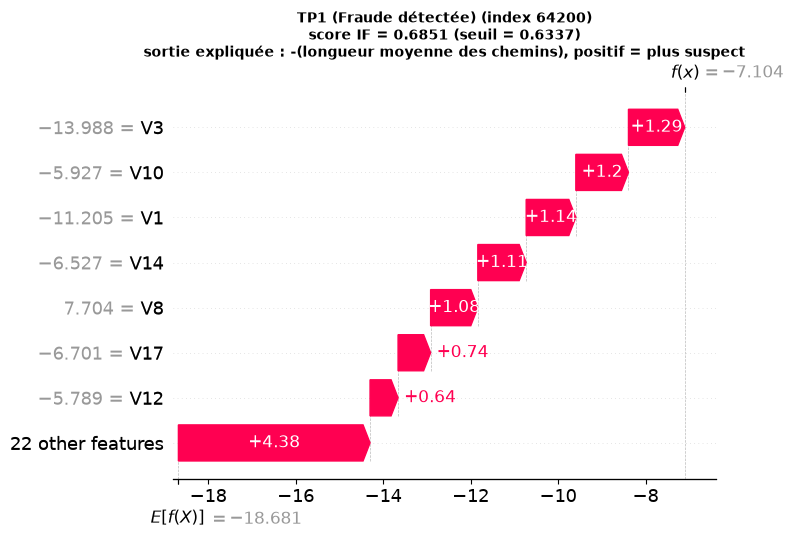

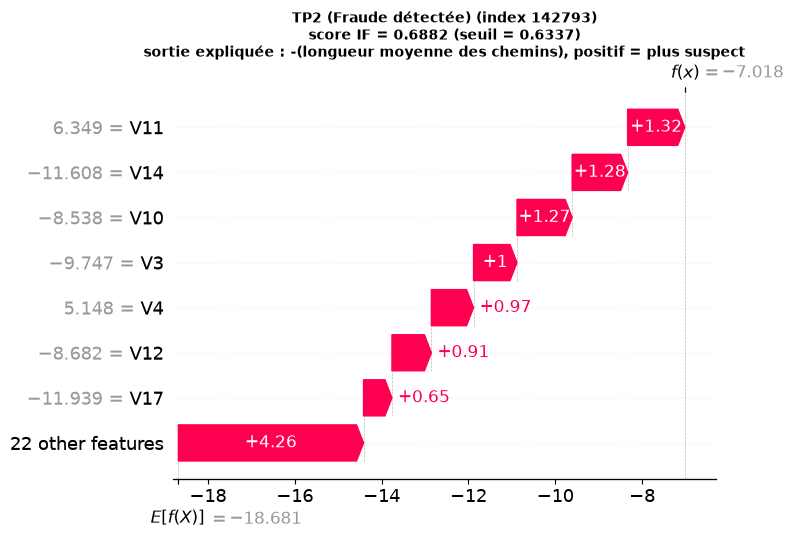

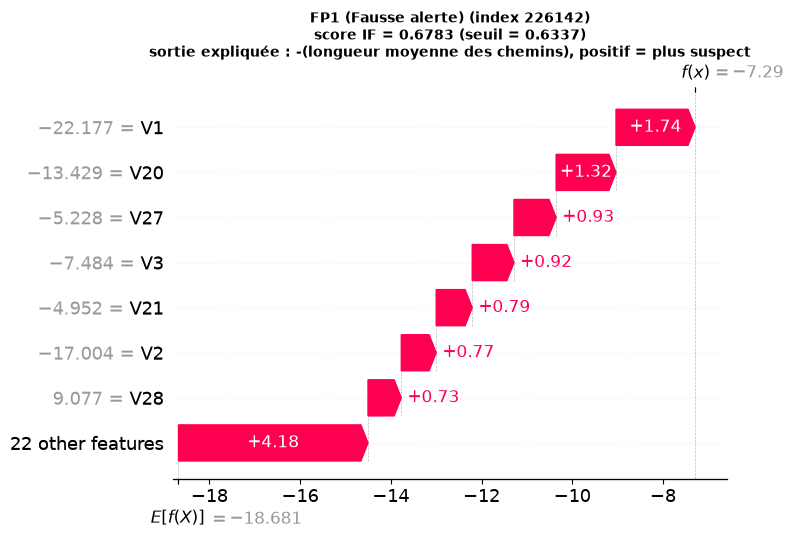

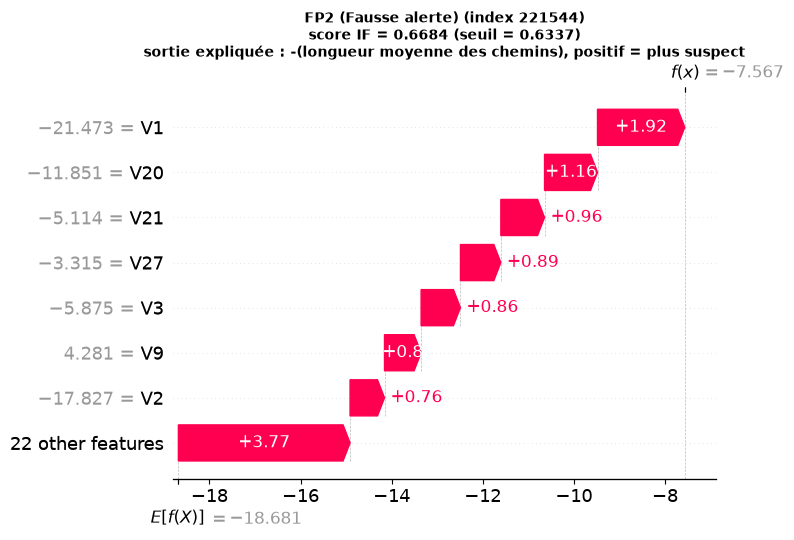

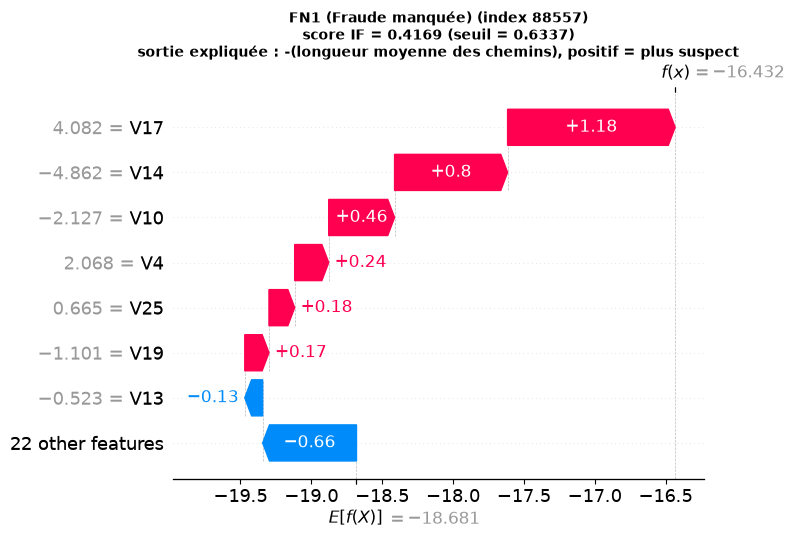

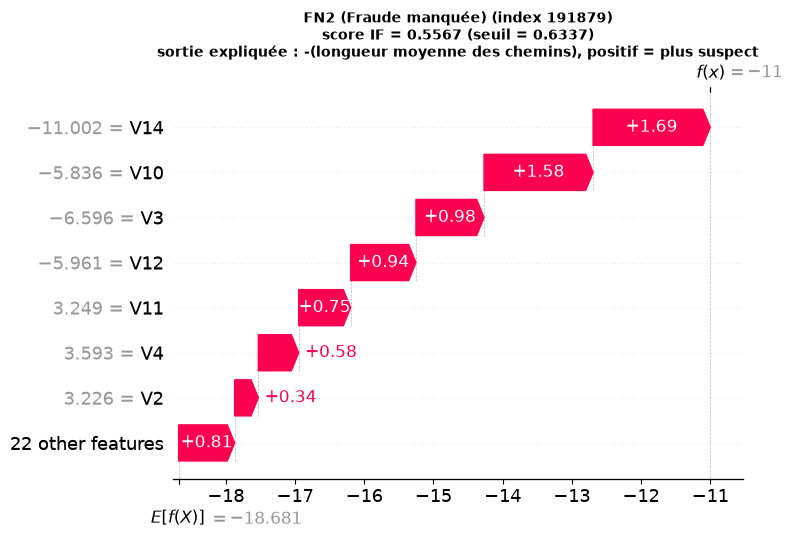

In [ ]:
# 5. Contributions et graphiques
display(utils_partie5.top_contributions(shap_values, obs_dict))
display(utils_partie5.importance_par_categorie(shap_values, obs_dict))
display(utils_partie5.contribution_signee_par_categorie(shap_values, obs_dict))
utils_partie5.plot_shap_waterfalls(
    shap_values, obs_dict, scores_test_if, seuil_if, X_test_s,
    libelle_sortie=libelle,
)

### Analyse et Interprétation des Explications SHAP (Isolation Forest)

### 1. Grandeur expliquée et sens des contributions

- **Grandeur expliquée :** `shap.TreeExplainer` appliqué à l'Isolation Forest explique la longueur moyenne de chemin `h(x)` (nombre moyen de coupes pour isoler une transaction), et non le score final. Le score est une transformation monotone décroissante de `h(x)` : plus le chemin est court, plus le score est élevé. La corrélation entre la somme des contributions et `-score_samples` vaut -0,998 sur un second échantillon de 50 observations du train (`random_state=0`, distinct du fond SHAP), ce qui confirme que la sortie brute est `h(x)`.
- **Référence :** l'espérance de `h(x)` sur le fond de 50 observations (`random_state=42`) vaut 13,288 coupes. Les contributions sont relatives à ce fond : une autre référence changerait les valeurs.
- **Convention retenue (après inversion) :** les contributions sont multipliées par -1, donc la sortie expliquée devient `f(x) = -h(x)`, de point de départ -13,288. Elle augmente avec la suspicion.
  - **Contribution positive :** la variable raccourcit le chemin, donc pousse vers l'alerte.
  - **Contribution négative :** la variable allonge le chemin, donc pousse vers la normalité.
- **Lien avec le seuil :** une transaction est alertée lorsque `-score_samples` atteint le seuil figé de 0,6337. Les contributions s'expriment en coupes : on ne compare pas leur somme au seuil.

### 2. Variables qui contribuent aux alertes (TP, FP, FN)

Deux tableaux sont utilisés :

- **Importance** (moyenne de |φ|, toujours positive, trié par TP) : indique quelles variables comptent dans chaque catégorie.
- **Contribution signée** (moyenne de φ) : indique dans quel sens chaque variable pousse en moyenne.

Les valeurs sont des moyennes sur deux cas par catégorie, choisis par ordre d'index. Deux cas peuvent se compenser, et l'échantillon ne permet pas de généraliser.

- **Fraudes détectées (TP1, TP2) :** les plus fortes contributions vers l'alerte sont V10 (+1,237), V14 (+1,192), V3 (+1,144), V11 (+0,867), V8 (+0,814) et V12 (+0,774). Plusieurs variables agissent ensemble pour raccourcir le chemin. Les scores des deux cas (0,6851 et 0,6882) dépassent le seuil de 0,6337.
- **Fausses alertes (FP1, FP2) :** les contributions vers l'alerte viennent surtout de V1 (+1,830), V20 (+1,241), V27 (+0,908), V3 (+0,892), V21 (+0,877), V2 (+0,763) et V28 (+0,735). V20, V21 et V28 sont quasi absentes chez les TP (+0,077, +0,150, +0,066) ; V10 (+0,208) et V14 (+0,075), moteurs des TP, y sont presque nulles. Ces transactions normales sont atypiques dans d'autres directions. Isolation Forest, sans étiquette, signale cette atypicité sans en distinguer la nature.
- **Fraudes manquées (FN1, FN2) :** V14 (+1,245), V10 (+1,020) et V17 (+0,689) poussent vers l'alerte, comme chez les TP. V7 (-0,072) et V8 (-0,066) poussent légèrement vers la normalité, alors qu'elles sont fortes chez les TP (V8 +0,814, V7 +0,573). Les scores des deux cas (0,4169 et 0,5567) restent sous le seuil de 0,6337. Les deux cas diffèrent : FN1 repose surtout sur V17, FN2 sur V14 et V10.
- **Amount :** la moyenne signée est faible (+0,067 en FN, +0,021 en FP, +0,059 en TP), mais son importance en FN (0,114) montre que ses deux cas vont dans des sens opposés. Sa valeur est mise à l'échelle par `RobustScaler`, pas exprimée en euros.

Un écart entre importance et moyenne signée signale des cas en désaccord. C'est aussi le cas pour V9 en FN (0,098 contre 0,040) et V6 en FP (0,035 contre -0,002) : ne leur donnez pas de sens stable sur deux cas.

**Synthèse :** les fraudes détectées cumulent des contributions fortes sur V10, V14 et V3. Les fausses alertes sont portées par V1, V20, V21, V27 et V28, quasi absentes chez les fraudes détectées. Les fraudes manquées ont un signal sur V14, V10 et V17, mais moins de variables poussent vers l'alerte que chez les fraudes détectées. Isolation Forest repère surtout l'atypicité, sans distinguer la fraude : sa précision sur le test est de 0,23, avec 119 fausses alertes.


### 3. Ce que SHAP permet et ne permet pas d'affirmer

- **Ce que SHAP décrit :** la contribution de chaque variable à la longueur de chemin calculée par les arbres, par rapport à un fond de 50 observations du train. C'est une description du modèle, pas une propriété du phénomène réel.
- **Causalité :** une variable qui pousse vers l'alerte n'est pas la cause de la fraude ; elle est seulement associée à un chemin court dans ce modèle.
- **Signification métier :** `V1` à `V28` sont des composantes anonymisées ; aucune interprétation métier n'en découle. `Amount` garde un sens concret, mais sa valeur est mise à l'échelle, pas exprimée en euros.
- **Portée :** six cas illustrent des mécanismes, sans permettre de conclure sur l'ensemble des alertes.